# Étude de cas 1 — Jalon 3 : Un nouveau scanner, deux tâches
**M2 SDIA – Advanced Artificial Intelligence – 2026-2027** ·

| § | Contenu |
|---|---|
| 0 | Environnement, graine, chargement des données, métriques, journal d'expériences |
| 1 | Vérification théorique : comptage des paramètres |
| 2 | Lecteur de départ et chute sur le scanner B (données brutes) |
| 3 | Caractérisation du décalage A → B (intensités, flou, motif, rotation) |
| 3bis | **Correction du décalage par normalisation par image** + test rapide de son effet |
| 3ter | **Lecteur renforcé** : choix d'architecture sur un pilote (lecture « à plat » ou « par emplacements »), entraînement sur A |
| 4 | Trois stratégies sur les 600 images de B (zéro / extraction / ajustement fin) + taux d'apprentissage |
| 5 | Augmentation de données imitant B (seule, puis combinée à l'ajustement fin) |
| 6 | Modèle multitâche, étude de λ, transfert de la détection à B |
| 7 | Sélection sur validation (λ, modèle, confiance), **évaluation unique sur le test**, mesure par rapport aux cibles |
| 8 | Reproductibilité (journal, modèles, `requirements.txt`, `README.md`) |

**Protocole** : tous les réglages se font sur la **validation**. L'ensemble de **test** n'est utilisé qu'une seule fois.

## 0. Environnement, graine et données

In [1]:
import os, sys, re, time, json, glob, random, platform, warnings
import importlib.metadata as md
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

SEED = 42
def fixer_graine(s=SEED):
    os.environ["PYTHONHASHSEED"] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
fixer_graine()

SORTIES = "sorties_jalon3"
SAUVEGARDE_DRIVE = True
if SAUVEGARDE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        SORTIES = "/content/drive/MyDrive/uc1_jalon3/sorties_jalon3"
    except Exception as e:
        print("Drive non disponible, sauvegarde locale seulement :", type(e).__name__)
os.makedirs(SORTIES, exist_ok=True)

VERSIONS = {"python": platform.python_version()}
for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "tensorflow", "keras"]:
    try: VERSIONS[p] = md.version(p)
    except Exception: VERSIONS[p] = "?"
print(VERSIONS)
print("GPU :", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'tensorflow': '2.21.0', 'keras': '3.13.2'}
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def trouver(nom):
    for base in [".", "data", "/content", "/content/data", "/mnt/user-data/attachments"]:
        trouves = glob.glob(os.path.join(base, "**", f"*{nom}.npz"), recursive=True)
        if trouves:
            return sorted(trouves)[0]
    raise FileNotFoundError(f"Fichier *{nom}.npz introuvable : placez-le dans data/ (voir README).")

def charger(chemin):
    with np.load(chemin) as f:
        return {k: f[k] for k in f.files}

A = charger(trouver("domaineA"))
B = charger(trouver("domaineB"))
SPLITS = ["train", "val", "test"]
XA = {s: (A["X_" + s].astype("float32") / 255.0)[..., None] for s in SPLITS}
XB = {s: (B["X_" + s].astype("float32") / 255.0)[..., None] for s in SPLITS}
print({s: XA[s].shape[0] for s in SPLITS}, {s: XB[s].shape[0] for s in SPLITS})

L_MAX, BLANC = 5, 10
def vers_positions(montants):
    Y = np.full((len(montants), L_MAX), BLANC, dtype="int64")
    for i, m in enumerate(montants):
        m = str(m); Y[i, L_MAX - len(m):] = [int(c) for c in m]
    return Y
def en_dict(Y):
    return {f"pos{k}": Y[:, k] for k in range(L_MAX)}

YA = {s: vers_positions(A["montant_" + s]) for s in SPLITS}
YB = {s: vers_positions(B["montant_" + s]) for s in SPLITS}

for nom, D in [("A", A), ("B", B)]:
    print(nom, "part d'altérés (train/val/test) :",
          [round(float(D["altere_" + s].mean()), 3) for s in SPLITS])

{'train': 15000, 'val': 3000, 'test': 5000} {'train': 600, 'val': 400, 'test': 3000}
A part d'altérés (train/val/test) : [0.099, 0.095, 0.099]
B part d'altérés (train/val/test) : [0.095, 0.11, 0.103]


In [3]:
def taux_automatisation(correct, conf, cible=0.99):
    ordre = np.argsort(-conf, kind="stable")
    c = np.asarray(correct, dtype=float)[ordre]
    cumul = np.cumsum(c) / np.arange(1, len(c) + 1)
    ok = np.where(cumul >= cible)[0]
    return 0.0 if len(ok) == 0 else float((ok[-1] + 1) / len(c))

class Ensemble:
    """Moyenne des probabilités de plusieurs modèles ayant les mêmes sorties."""
    def __init__(self, modeles): self.models = list(modeles)
    def predict(self, X, batch_size=512, verbose=0):
        Ps = [sorties_dict(m, X) for m in self.models]
        return {k: np.mean([P[k] for P in Ps], axis=0) for k in Ps[0]}

def noms_sorties(m):
    if isinstance(m, Ensemble): m = m.models[0]
    o = m.output
    return list(o.keys()) if isinstance(o, dict) else list(m.output_names)

def sorties_dict(m, X):
    P = m.predict(X, batch_size=512, verbose=0)
    if isinstance(P, (list, tuple)):
        P = dict(zip(noms_sorties(m), P))
    return P

MODE_CONF = "prod"
def lire(m, X, mode=None):
    mode = mode or MODE_CONF
    P = sorties_dict(m, X)
    probs = np.stack([P[f"pos{k}"] for k in range(L_MAX)], axis=1)
    pred = probs.argmax(-1)
    mx = probs.max(-1)
    if mode == "prod": conf = mx.prod(-1)
    elif mode == "min": conf = mx.min(-1)
    else: conf = mx.mean(-1)          # "moy"
    lus = np.array(["".join(str(d) for d in l if d != BLANC) for l in pred])
    return lus, conf, P

def auc_alt(y, p):
    y = np.asarray(y).ravel()
    return float(roc_auc_score(y, np.asarray(p).ravel())) if len(np.unique(y)) == 2 else float("nan")

def evaluer(m, dom, split, mode=None):
    X, D = (XA, A) if dom == "A" else (XB, B)
    lus, conf, P = lire(m, X[split], mode)
    corr = (lus == D["montant_" + split])
    r = {"exact": float(corr.mean()), "auto": taux_automatisation(corr, conf)}
    if "altere" in P:
        r["auc_alt"] = auc_alt(D["altere_" + split], P["altere"])
    return r

def cibles(D, Y, split, m):
    d = en_dict(Y[split])
    if "altere" in noms_sorties(m):
        d["altere"] = D["altere_" + split].astype("float32").reshape(-1, 1)
    return d

def set_lr(opt, lr):
    lr = float(lr)
    try:
        opt.learning_rate.assign(lr)
    except Exception:
        try:
            keras.backend.set_value(opt.learning_rate, lr)
        except Exception:
            opt.learning_rate = lr

In [4]:
JOURNAL = []
FICHIER_JOURNAL = os.path.join(SORTIES, "journal_jalon3.jsonl")
open(FICHIER_JOURNAL, "w").close()

def jr(nom, config, resultats, commentaire=""):
    ligne = {"jalon": 3, "date": datetime.now().isoformat(timespec="seconds"), "essai": nom,
             "config": config, "resultats": resultats, "commentaire": commentaire}
    JOURNAL.append(ligne)
    with open(FICHIER_JOURNAL, "a") as f:
        f.write(json.dumps(ligne, default=float, ensure_ascii=False) + "\n")
    if "journaliser" in globals():
        try:
            journaliser(jalon=3, nom=nom, config=config, resultats=resultats, commentaire=commentaire)
        except Exception as e:
            print("(journaliser du notebook de démarrage non appelé :", type(e).__name__, ")")

## 1. Vérification théorique — comptage des paramètres

| Couche | Calcul | Paramètres |
|---|---|---|
| Conv 32 | 3·3·1·32 + 32 | 320 |
| Conv 64 | 3·3·32·64 + 64 | 18 496 |
| Conv 64 | 3·3·64·64 + 64 | 36 928 |
| Flatten | 4·16·64 | 4 096 valeurs |
| Dense 128 | 4096·128 + 128 | 524 416 |
| 5 têtes softmax | 5·(128·11 + 11) | 7 095 |
| **Total** | | **587 255** |

Convolutions gelées : 55 744 figés (**9,5 %**) ; reste **531 511 entraînables (90,5 %)**. Conclusion : geler les convolutions ne régularise presque rien → proposer un 4ᵉ bloc + dense 64 (idée reprise par le lecteur renforcé du 3ter).

In [5]:
def cnn_lecteur(filtres=(32, 64, 64), dense=128):
    entree = keras.Input((32, 128, 1))
    x = entree
    for f in filtres:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense, activation="relu", name="dense_lecture")(x)
    x = layers.Dropout(0.3)(x)
    sorties = {f"pos{k}": layers.Dense(11, activation="softmax", name=f"pos{k}")(x) for k in range(L_MAX)}
    return keras.Model(entree, sorties, name="cnn_lecteur")

def compter(m):
    total = m.count_params()
    conv = sum(l.count_params() for l in m.layers if isinstance(l, layers.Conv2D))
    return total, conv, total - conv

for nom, mm in [("lecteur de départ", cnn_lecteur()),
                ("proposition : 4 blocs + dense 64", cnn_lecteur((32, 64, 64, 64), 64))]:
    total, conv, reste = compter(mm)
    print(f"{nom:36s} total={total:>8,}  convolutions={conv:>7,} ({conv/total:5.1%})  "
          f"entraînables si convolutions gelées={reste:>8,} ({reste/total:5.1%})")
assert compter(cnn_lecteur()) == (587255, 55744, 531511), "comptage à la main non retrouvé"

lecteur de départ                    total= 587,255  convolutions= 55,744 ( 9.5%)  entraînables si convolutions gelées= 531,511 (90.5%)
proposition : 4 blocs + dense 64     total= 161,847  convolutions= 92,672 (57.3%)  entraînables si convolutions gelées=  69,175 (42.7%)


## 2. Lecteur de départ et chute sur le scanner B

In [6]:
PERTES = {f"pos{k}": "sparse_categorical_crossentropy" for k in range(L_MAX)}

fixer_graine()
lecteur_A = cnn_lecteur()
lecteur_A.compile(keras.optimizers.Adam(1e-3), loss=PERTES)
t0 = time.perf_counter()
lecteur_A.fit(XA["train"], en_dict(YA["train"]), epochs=15, batch_size=128,
              validation_data=(XA["val"], en_dict(YA["val"])), verbose=2)
TEMPS_DEPART = time.perf_counter() - t0
lecteur_A.save(os.path.join(SORTIES, "lecteur_A.keras"))

res_depart = {d: evaluer(lecteur_A, d, "val") for d in ["A", "B"]}
chute = pd.DataFrame(res_depart).T.rename(columns={"exact": "montants exacts", "auto": "taux d'automatisation"})
display(chute)
print(f"Chute de la part de montants exacts A → B : {res_depart['A']['exact']:.3f} → {res_depart['B']['exact']:.3f}")
jr("lecteur_depart", {"train": "A", "epochs": 15, "lr": 1e-3}, res_depart,
   "Référence : lecteur appris sur A seul, évalué sans adaptation sur la validation de A et de B.")

Epoch 1/15
118/118 - 24s - 205ms/step - loss: 8.9745 - pos0_loss: 0.7512 - pos1_loss: 1.5078 - pos2_loss: 2.1039 - pos3_loss: 2.3252 - pos4_loss: 2.2837 - val_loss: 7.6054 - val_pos0_loss: 0.5957 - val_pos1_loss: 1.2609 - val_pos2_loss: 1.7751 - val_pos3_loss: 2.0305 - val_pos4_loss: 1.9418
Epoch 2/15
118/118 - 2s - 20ms/step - loss: 7.2333 - pos0_loss: 0.5840 - pos1_loss: 1.2429 - pos2_loss: 1.7435 - pos3_loss: 1.9540 - pos4_loss: 1.7071 - val_loss: 5.9900 - val_pos0_loss: 0.5291 - val_pos1_loss: 1.0632 - val_pos2_loss: 1.4555 - val_pos3_loss: 1.6717 - val_pos4_loss: 1.2675
Epoch 3/15
118/118 - 2s - 19ms/step - loss: 6.1064 - pos0_loss: 0.5259 - pos1_loss: 1.0888 - pos2_loss: 1.5312 - pos3_loss: 1.7225 - pos4_loss: 1.2343 - val_loss: 5.1140 - val_pos0_loss: 0.5009 - val_pos1_loss: 0.9987 - val_pos2_loss: 1.3051 - val_pos3_loss: 1.4659 - val_pos4_loss: 0.8409
Epoch 4/15
118/118 - 2s - 19ms/step - loss: 5.4166 - pos0_loss: 0.4814 - pos1_loss: 0.9900 - pos2_loss: 1.4100 - pos3_loss: 1.56

,montants exacts,taux d'automatisation
A,0.411333,0.078667
B,0.000000,0.000000


Chute de la part de montants exacts A → B : 0.411 → 0.000


## 3. Caractérisation du décalage entre les scanners

In [7]:
def echantillon(X, n=1500, graine=0):
    idx = np.random.default_rng(graine).choice(len(X), min(n, len(X)), replace=False)
    return X[idx][..., 0]

XA_e, XB_e = echantillon(XA["train"]), echantillon(XB["train"], 600)

def stats_intensites(X2):
    fond = np.median(X2.reshape(len(X2), -1), axis=1)
    encre = np.percentile(X2.reshape(len(X2), -1), 99, axis=1)
    return {"fond (médiane)": fond.mean(), "encre (p99)": encre.mean(),
            "contraste (p99 - fond)": (encre - fond).mean(), "écart-type pixels": X2.std()}

def nettete(X2):
    out = []
    for im in X2:
        c = np.percentile(im, 99) - np.median(im)
        out.append(ndimage.laplace(im).var() / max(c, 1e-3) ** 2)
    return float(np.mean(out))

def angle_image(im):
    w = np.clip(im - np.median(im), 0, None)
    if w.max() <= 0: return np.nan
    w = np.where(w > 0.5 * w.max(), w, 0)
    ys, xs = np.mgrid[0:im.shape[0], 0:im.shape[1]]
    s = w.sum(); cx, cy = (w * xs).sum() / s, (w * ys).sum() / s
    mu20 = (w * (xs - cx) ** 2).sum() / s; mu02 = (w * (ys - cy) ** 2).sum() / s
    mu11 = (w * (xs - cx) * (ys - cy)).sum() / s
    return float(np.degrees(0.5 * np.arctan2(2 * mu11, mu20 - mu02)))

def angles(X, D, split, n=1500):
    longs = np.array([len(m) for m in D["montant_" + split]])
    idx = np.where(longs >= 4)[0][:n]
    return np.array([angle_image(X[split][i, ..., 0]) for i in idx])

ang_A, ang_B = angles(XA, A, "train"), angles(XB, B, "train")

tab = pd.DataFrame({"A": stats_intensites(XA_e), "B": stats_intensites(XB_e)})
tab.loc["netteté (lap²/contraste²)"] = [nettete(XA_e[:600]), nettete(XB_e)]
tab.loc["angle moyen (°)"] = [np.nanmean(ang_A), np.nanmean(ang_B)]
tab.loc["angle écart-type (°)"] = [np.nanstd(ang_A), np.nanstd(ang_B)]
display(tab.round(4))

,A,B
fond (médiane),0.0000,0.1745
encre (p99),0.9067,0.7417
contraste (p99 - fond),0.9067,0.5673
écart-type pixels,0.2512,0.1648
netteté (lap²/contraste²),0.0707,0.1348
angle moyen (°),-0.4883,0.0423
angle écart-type (°),2.6255,3.8738


In [8]:
GABARIT = np.median(XB["train"][..., 0], axis=0)
stabilite = float(np.std(XB_e.mean(0)) / (XB_e.std() / np.sqrt(len(XB_e))))
print(f"Gabarit : min={GABARIT.min():.3f} max={GABARIT.max():.3f} ; ratio stabilisation = {stabilite:.1f} (≫ 1 : motif fixe)")

Tf = GABARIT.ravel(); coefs, resid = [], []
for im in XB_e:
    bg = (im < GABARIT + 0.06).ravel()
    M = np.stack([Tf[bg], np.ones(bg.sum())], 1)
    c = np.linalg.lstsq(M, im.ravel()[bg], rcond=None)[0]
    coefs.append(c); resid.append(im.ravel()[bg] - M @ c)
coefs = np.array(coefs)
PARAMS_B = {"a_moy": float(coefs[:, 0].mean()), "a_std": float(coefs[:, 0].std()),
            "b_moy": float(coefs[:, 1].mean()), "b_std": float(coefs[:, 1].std()),
            "bruit": float(np.concatenate(resid).std())}
RB = XB_e - (coefs[:, 0, None, None] * GABARIT + coefs[:, 1, None, None])
PARAMS_B["gain"] = float(np.percentile(RB.reshape(len(RB), -1), 99.5, axis=1).mean() /
                         np.percentile(XA_e.reshape(len(XA_e), -1), 99.5, axis=1).mean())
PARAMS_B["sigma_flou"] = 0.3
d_moy = abs(np.nanmean(ang_B) - np.nanmean(ang_A))
d_std = float(np.sqrt(max(np.nanvar(ang_B) - np.nanvar(ang_A), 0.0)))
PARAMS_B["rot_max"] = float(max(d_moy + 2 * d_std, 1.0))
print("Paramètres estimés pour imiter le scanner B :")
print(json.dumps(PARAMS_B, indent=2))
jr("decalage_AB", {"echantillon": "train A (1500) / train B (600)"},
   {"params_estimes": PARAMS_B, "intensites": tab.round(4).to_dict()},
   "Caractérisation : intensités, flou, motif, rotation. σ initialisé à 0,3.")

Gabarit : min=0.141 max=0.365 ; ratio stabilisation = 9.6 (≫ 1 : motif fixe)
Paramètres estimés pour imiter le scanner B :
{
  "a_moy": 0.4127542295622218,
  "a_std": 0.14516483046482412,
  "b_moy": 0.07594792335431175,
  "b_std": 0.029116689017219866,
  "bruit": 0.04845969109365508,
  "gain": 0.6628660468737134,
  "sigma_flou": 0.3,
  "rot_max": 6.227413972118125
}


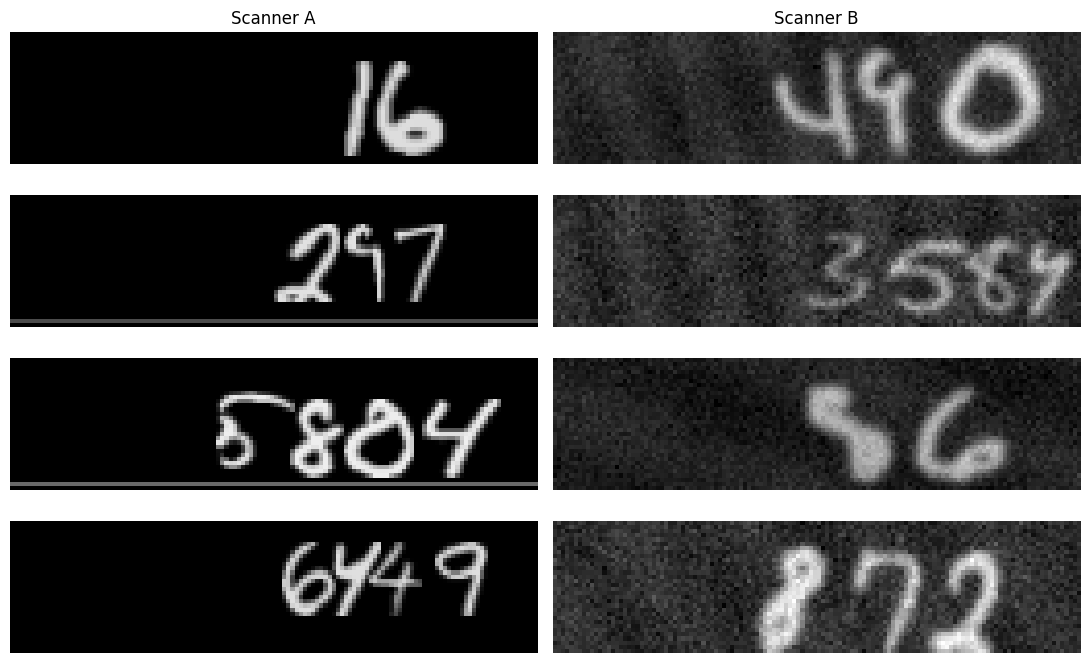

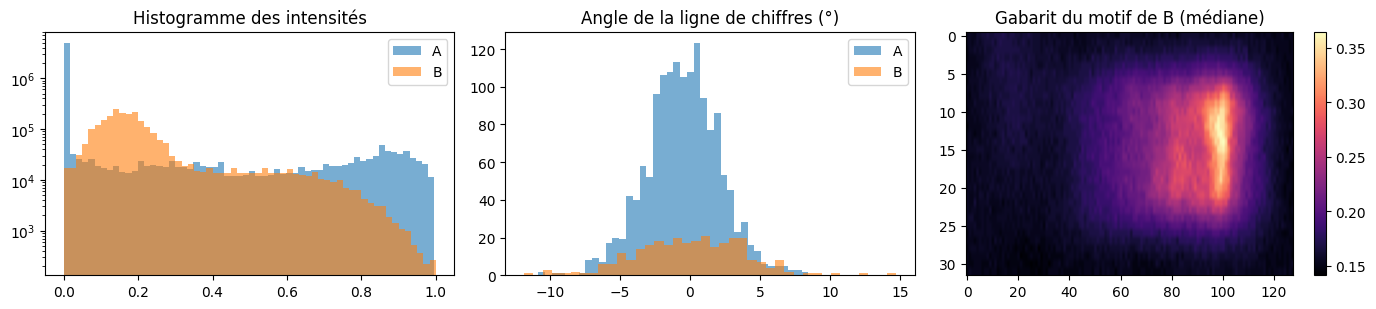

In [9]:
fig, axs = plt.subplots(4, 2, figsize=(11, 7))
for j, (nom, X) in enumerate([("A", XA["train"]), ("B", XB["train"])]):
    for i in range(4):
        axs[i, j].imshow(X[i, ..., 0], cmap="gray", vmin=0, vmax=1); axs[i, j].axis("off")
    axs[0, j].set_title(f"Scanner {nom}")
plt.tight_layout(); plt.savefig(os.path.join(SORTIES, "exemples_AB.png"), dpi=120); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))
axs[0].hist(XA_e.ravel(), bins=60, alpha=.6, label="A", log=True); axs[0].hist(XB_e.ravel(), bins=60, alpha=.6, label="B", log=True)
axs[0].set_title("Histogramme des intensités"); axs[0].legend()
axs[1].hist(ang_A[~np.isnan(ang_A)], bins=40, alpha=.6, label="A"); axs[1].hist(ang_B[~np.isnan(ang_B)], bins=40, alpha=.6, label="B")
axs[1].set_title("Angle de la ligne de chiffres (°)"); axs[1].legend()
im = axs[2].imshow(GABARIT, cmap="magma", aspect="auto")
axs[2].set_title("Gabarit du motif de B (médiane)"); plt.colorbar(im, ax=axs[2])
plt.tight_layout(); plt.savefig(os.path.join(SORTIES, "decalage_AB.png"), dpi=120); plt.show()

## 3bis. Correction du décalage : normalisation par image

La caractérisation du 3 montre que B diffère surtout par le **fond** (0,17 au lieu de 0) et le **contraste** (0,57 au lieu de 0,91). On corrige cela **image par image** : fond = médiane des pixels, encre = percentile 99,5, puis mise à l'échelle dans [0, 1]. Aucune étiquette de B n'est utilisée : c'est un prétraitement appliqué aux deux scanners. Le motif de fond, le bruit, le flou et la rotation restent à traiter par l'augmentation et l'ajustement fin.

Un test rapide (MLP de scikit-learn lisant **seulement le dernier chiffre**, entraîné sur A, évalué sur B sans aucune adaptation) mesure l'effet avant de lancer les entraînements profonds.

In [10]:
def normaliser(X, bloc=2000):
    """Normalisation par image : fond (médiane) -> 0, encre (percentile 99,5) -> 1. X : (N, H, W, 1)."""
    X = np.asarray(X, dtype="float32"); out = np.empty_like(X)
    for i in range(0, len(X), bloc):
        x = X[i:i + bloc]; flat = x.reshape(len(x), -1)
        bg = np.median(flat, axis=1)[:, None, None, None]
        hi = np.percentile(flat, 99.5, axis=1)[:, None, None, None]
        out[i:i + bloc] = np.clip((x - bg) / np.maximum(hi - bg, 1e-3), 0, 1)
    return out

# Données brutes conservées (pour l'augmentation) ; XA / XB deviennent les versions normalisées.
if "XA_raw" not in globals():
    XA_raw, XB_raw = XA, XB
    XA = {s: normaliser(XA_raw[s]) for s in SPLITS}
    XB = {s: normaliser(XB_raw[s]) for s in SPLITS}

# --- Test rapide : lire le dernier chiffre (MLP), A -> B sans adaptation, brut vs normalisé ---
from sklearn.neural_network import MLPClassifier
dernier = lambda D, s: np.array([int(m[-1]) for m in D["montant_" + s]])
rogner = lambda X: X[:, ::2, 88::2, 0].reshape(len(X), -1)        # 40 dernières colonnes, sous-échantillonnées
PROXY = []
for nom, (XAt, XAv, XBv) in {"brut": (XA_raw["train"], XA_raw["val"], XB_raw["val"]),
                             "normalisé": (XA["train"], XA["val"], XB["val"])}.items():
    clf = MLPClassifier((256,), max_iter=40, early_stopping=True, random_state=0).fit(rogner(XAt), dernier(A, "train"))
    PROXY.append({"entrée": nom, "dernier chiffre juste, A (val)": clf.score(rogner(XAv), dernier(A, "val")),
                  "dernier chiffre juste, B (val)": clf.score(rogner(XBv), dernier(B, "val"))})
PROXY = pd.DataFrame(PROXY); display(PROXY.round(3))
jr("normalisation_par_image", {"test": "MLP dernier chiffre, A->B sans adaptation"}, PROXY.to_dict("records"),
   "Effet de la normalisation par image sur le décalage, sans étiquette B.")

,entrée,"dernier chiffre juste, A (val)","dernier chiffre juste, B (val)"
0,brut,0.758,0.220
1,normalisé,0.751,0.652


## 3ter. Lecteur renforcé (base des 4 à 7)

Deux architectures en concurrence sur un **pilote** (20 époques, sans augmentation, sur A normalisé) ; le choix se fait sur l'exact de la validation de A.

* **« plat »** : lecteur de la v5 — 4 blocs *Conv → BatchNorm → ReLU → MaxPool* (32, 64, 128, 128), `Flatten`, `Dense(128)`, 5 têtes.
* **« slots »** : tronc convolutif qui conserve l'axe horizontal (3 pooling, 4×16 cases), puis **5 attentions sur les colonnes** (une par emplacement de chiffre, avec biais de position appris) qui extraient 5 vecteurs ; un **même** classifieur `Dense(128) → Dense(11)` lit les 5 emplacements. La tête d'altération voit les 5 emplacements et le maximum sur les colonnes.

Le lecteur retenu est ensuite entraîné `EPOCHS_A` époques avec un taux d'apprentissage cosinus (10⁻³ → 10⁻⁵).

In [11]:
def bloc_conv(x, f, pool=True):
    x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D(2)(x) if pool else x

def tronc_fort(entree):                      # architecture « plat » (v5)
    x = entree
    for f in (32, 64, 128, 128):
        x = bloc_conv(x, f)
    return layers.Flatten()(x)

@keras.utils.register_keras_serializable(package="uc1")
class AjoutPosition(layers.Layer):
    """Ajoute un biais appris par position (colonne ou emplacement de chiffre)."""
    def build(self, input_shape):
        self.pos = self.add_weight(shape=tuple(input_shape[1:]), initializer="random_normal", name="pos")
    def call(self, x):
        return x + self.pos

def tronc_carte(entree):                     # architecture « slots » : carte (4 x 16 x 128)
    x = entree
    for f in (32, 64, 128):
        x = bloc_conv(x, f)
    return bloc_conv(x, 128, pool=False)

def lecture_slots(carte, dim=128):
    h, w, c = carte.shape[1], carte.shape[2], carte.shape[3]
    x = layers.Permute((2, 1, 3))(carte)                  # (B, 16, 4, 128)
    x = layers.Reshape((w, h * c))(x)                     # (B, 16, 512) : un vecteur par colonne
    cols = layers.Dense(dim, activation="relu", name="colonnes")(x)
    cols = AjoutPosition(name="pos_colonnes")(cols)
    att = layers.Softmax(axis=1, name="attention")(layers.Dense(L_MAX, name="att_logits")(cols))   # (B, 16, 5)
    slots = layers.Dot(axes=(1, 1), name="slots")([att, cols])                                     # (B, 5, dim)
    return cols, slots

def tetes_slots(slots):
    s = AjoutPosition(name="pos_slots")(slots)
    hh = layers.Dense(128, activation="relu", name="dense_lecture")(s)     # partagé par les 5 emplacements
    hh = layers.Dropout(0.3)(hh)
    logits = layers.Dense(11, name="logits_chiffre")(hh)                    # (B, 5, 11)
    sorties = {}
    for k in range(L_MAX):
        z = layers.Cropping1D((k, L_MAX - 1 - k))(logits)
        z = layers.Reshape((11,))(z)
        sorties[f"pos{k}"] = layers.Activation("softmax", name=f"pos{k}")(z)
    return sorties

def branche_alt(cols, slots):
    a = layers.Concatenate()([layers.Flatten()(slots), layers.GlobalMaxPooling1D()(cols)])
    a = layers.Dense(64, activation="relu", name="dense_alt")(a)
    a = layers.Dropout(0.3)(a)
    return layers.Dense(1, activation="sigmoid", name="altere")(a)

def construire_modele(archi, multitache=False):
    entree = keras.Input((32, 128, 1))
    if archi == "slots":
        cols, slots = lecture_slots(tronc_carte(entree))
        sorties = tetes_slots(slots)
        if multitache: sorties["altere"] = branche_alt(cols, slots)
    else:
        f = tronc_fort(entree)
        x = layers.Dense(128, activation="relu", name="dense_lecture")(f)
        x = layers.Dropout(0.3)(x)
        sorties = {f"pos{k}": layers.Dense(11, activation="softmax", name=f"pos{k}")(x) for k in range(L_MAX)}
        if multitache:
            y = layers.Dense(64, activation="relu", name="dense_alt")(f)
            y = layers.Dropout(0.3)(y)
            sorties["altere"] = layers.Dense(1, activation="sigmoid", name="altere")(y)
    return keras.Model(entree, sorties, name=f"cnn_{archi}" + ("_mt" if multitache else ""))

def lr_cosinus(lr0, ep, n, lr_min=1e-5):
    return float(lr_min + 0.5 * (lr0 - lr_min) * (1 + np.cos(np.pi * ep / n)))

EPOCHS_A = 50

def entrainer_base(archi, epochs, seed=0):
    fixer_graine(seed)
    m = construire_modele(archi)
    m.compile(keras.optimizers.Adam(1e-3), loss=PERTES)
    t0 = time.perf_counter()
    m.fit(XA["train"], en_dict(YA["train"]), epochs=epochs, batch_size=128, verbose=0,
          callbacks=[keras.callbacks.LearningRateScheduler(lambda ep, lr: lr_cosinus(1e-3, ep, epochs))])
    return m, time.perf_counter() - t0

# --- pilote : 20 époques par architecture, choix sur la validation de A ---
PILOTE = []
for archi in ["plat", "slots"]:
    m, dt = entrainer_base(archi, 20)
    rA, rB = evaluer(m, "A", "val"), evaluer(m, "B", "val")
    PILOTE.append({"archi": archi, "params": m.count_params(), "A_exact": rA["exact"], "B_exact": rB["exact"], "temps_s": dt})
    print(f"pilote {archi:6s} params={m.count_params():>8,}  exact A={rA['exact']:.3f}  exact B (sans adaptation)={rB['exact']:.3f}  {dt:.0f}s")
PILOTE = pd.DataFrame(PILOTE); display(PILOTE.round(3))
ARCHI = str(PILOTE.loc[PILOTE["A_exact"].idxmax(), "archi"])
print("Architecture retenue (validation A) :", ARCHI)
jr("pilote_architecture", {"epochs": 20, "critere": "exact val A"}, {"retenue": ARCHI, "table": PILOTE.round(4).to_dict("records")},
   "Choix entre lecture « plat » (v5) et lecture « slots » sur un pilote.")

# --- lecteur renforcé retenu, entraîné sur A (normalisé) ---
LECTEUR_BASE, TEMPS_BASE = entrainer_base(ARCHI, EPOCHS_A)
LECTEUR_BASE.save(os.path.join(SORTIES, "lecteur_A_renforce.keras"))
res_base = {d: evaluer(LECTEUR_BASE, d, "val") for d in ["A", "B"]}
display(pd.DataFrame(res_base).T.rename(columns={"exact": "montants exacts", "auto": "taux d'automatisation"}))
print(f"lecteur renforcé ({ARCHI}) : {LECTEUR_BASE.count_params():,} paramètres ; {TEMPS_BASE:.0f}s")
jr("lecteur_renforce", {"train": "A normalisé", "epochs": EPOCHS_A, "lr": "cosinus 1e-3 -> 1e-5", "archi": ARCHI},
   res_base, "Base du transfert : normalisation par image + lecture retenue sur pilote.")

pilote plat   params= 510,679  exact A=0.414  exact B (sans adaptation)=0.158  73s


pilote slots  params= 328,240  exact A=0.610  exact B (sans adaptation)=0.468  73s


,archi,params,A_exact,B_exact,temps_s
0,plat,510679,0.414,0.158,72.715
1,slots,328240,0.610,0.468,73.264


Architecture retenue (validation A) : slots


,montants exacts,taux d'automatisation
A,0.615667,0.003333
B,0.427500,0.095000


lecteur renforcé (slots) : 328,240 paramètres ; 152s


In [12]:
# Fonctions d'augmentation imitant le scanner B (paramètres estimés au 3) ; utilisées dès le 4 et au 5.
COMPOSANTES = ("rotation", "flou", "contraste", "motif", "bruit")

def _aug_chunk(X, params, graine, composantes, p):
    rng = np.random.default_rng(graine)
    N, H, W = X.shape[:3]
    out = X.copy()
    appliquer = rng.random(N) < p
    for i in np.where(appliquer)[0]:
        im = X[i, ..., 0]
        if "rotation" in composantes:
            im = ndimage.rotate(im, rng.uniform(-params["rot_max"], params["rot_max"]),
                                reshape=False, order=1, mode="nearest")
        if "flou" in composantes and params["sigma_flou"] > 0:
            im = ndimage.gaussian_filter(im, params["sigma_flou"] * rng.uniform(0.7, 1.3))
        if "contraste" in composantes:
            im = params["gain"] * rng.uniform(0.9, 1.1) * im
        if "motif" in composantes:
            a_ = max(rng.normal(params["a_moy"], params["a_std"]), 0.0)
            im = im + a_ * params["gabarit"] + rng.normal(params["b_moy"], params["b_std"])
        if "bruit" in composantes:
            im = im + rng.normal(0, params["bruit"], im.shape)
        out[i, ..., 0] = np.clip(im, 0, 1)
    return out

def augmenter(X, params=None, rng=None, composantes=COMPOSANTES, p=1.0, n_jobs=2):
    params = {**(params or PARAMS_B), "gabarit": GABARIT}
    rng = rng or np.random.default_rng()
    if len(X) < 2000 or n_jobs == 1:
        return _aug_chunk(X, params, int(rng.integers(2**31 - 1)), composantes, p)
    graines = rng.integers(0, 2**31 - 1, n_jobs)
    parts = np.array_split(np.arange(len(X)), n_jobs)
    try:
        from joblib import Parallel, delayed
        sorties = Parallel(n_jobs=n_jobs)(delayed(_aug_chunk)(X[idx], params, int(g), composantes, p)
                                          for idx, g in zip(parts, graines))
        return np.concatenate(sorties)
    except Exception:
        return _aug_chunk(X, params, int(graines[0]), composantes, p)

## 4. Trois stratégies sur les 600 images étiquetées de B

In [13]:
SEEDS = [0, 1, 2]
MODELES = {}

def copie(m):
    c = keras.models.clone_model(m); c.set_weights(m.get_weights()); return c

def regler(m, convs_geles=False, dense_gele=False):
    for l in m.layers:
        if isinstance(l, (layers.Conv2D, layers.BatchNormalization)): l.trainable = not convs_geles
        if l.name == "dense_lecture": l.trainable = not dense_gele
    return m

def pertes_de(m):
    return {n: ("binary_crossentropy" if n == "altere" else "sparse_categorical_crossentropy") for n in noms_sorties(m)}

def compiler(m, lr, poids=None):
    m.compile(keras.optimizers.Adam(lr), loss=pertes_de(m), loss_weights=poids)

AUG_B = True                                   # légère augmentation des 600 images de B pendant l'ajustement
PARAMS_DOUX = {**PARAMS_B, "rot_max": 2.0, "bruit": 0.01}
COMP_DOUX = ("rotation", "bruit")

def entrainer_B(m, lr, epochs=100, patience=10, bs=32, poids=None, seed=0, aug=None):
    """Entraînement sur les 600 images de B ; arrêt précoce sur val_loss (meilleurs poids restaurés)."""
    aug = AUG_B if aug is None else aug
    fixer_graine(seed)
    compiler(m, lr, poids)
    rng = np.random.default_rng(seed)
    ytr, yva = cibles(B, YB, "train", m), cibles(B, YB, "val", m)
    meilleur, meilleurs_poids, attente, n_ep = np.inf, m.get_weights(), 0, 0
    t0 = time.perf_counter()
    for ep in range(epochs):
        Xtr = (normaliser(augmenter(XB_raw["train"], params=PARAMS_DOUX, rng=rng, composantes=COMP_DOUX, p=0.5))
               if aug else XB["train"])
        h = m.fit(Xtr, ytr, validation_data=(XB["val"], yva), epochs=1, batch_size=bs, verbose=0)
        n_ep += 1
        v = h.history["val_loss"][0]
        if v < meilleur - 1e-4:
            meilleur, meilleurs_poids, attente = v, m.get_weights(), 0
        else:
            attente += 1
            if attente >= patience: break
    m.set_weights(meilleurs_poids)
    return n_ep, time.perf_counter() - t0

TABLE_B = []
def essai_B(nom, construire, lr, commentaire=""):
    lignes = []
    for s in SEEDS:
        m = construire(s)
        n_ep, dt = entrainer_B(m, lr, seed=s)
        r = evaluer(m, "B", "val"); r.update(epochs=n_ep, temps_s=dt)
        lignes.append(r)
        if s == SEEDS[0]: MODELES[nom] = m
    df = pd.DataFrame(lignes)
    ligne = {"stratégie": nom, "lr": lr}
    for c in ["exact", "auto", "epochs", "temps_s"]:
        ligne[c] = df[c].mean(); ligne[c + "_std"] = df[c].std()
    TABLE_B.append(ligne)
    jr(nom, {"lr": lr, "graines": SEEDS, "images_B": 600, "aug_B": AUG_B}, {k: v for k, v in ligne.items() if k not in ("stratégie",)}, commentaire)
    print(f"{nom:34s} lr={lr:<8g} exact(val B)={ligne['exact']:.3f} ± {ligne['exact_std']:.3f}   "
          f"auto={ligne['auto']:.3f}   {ligne['epochs']:.0f} ép.   {ligne['temps_s']:.0f}s")

def construire_zero(s):
    fixer_graine(s); return construire_modele(ARCHI)
def construire_extraction(convs=True, dense=False):
    return lambda s: regler(copie(LECTEUR_BASE), convs_geles=convs, dense_gele=dense)
def construire_fine(s):
    return regler(copie(LECTEUR_BASE), convs_geles=False, dense_gele=False)

for _nom, _r in [("sans adaptation (lecteur de départ)", res_depart), ("sans adaptation (lecteur renforcé)", res_base)]:
    TABLE_B.append({"stratégie": _nom, "lr": np.nan, "exact": _r["B"]["exact"], "auto": _r["B"]["auto"],
                    "exact_std": 0, "epochs": 0, "temps_s": 0})

essai_B("de zéro sur B", construire_zero, 1e-3, "Entraînement complet sur 600 images (risque de sur-apprentissage).")
essai_B("extraction (convs gelées)", construire_extraction(True, False), 1e-3, "Dense + têtes réentraînées ; BatchNorm du tronc gelée aussi.")
essai_B("extraction (têtes seules)", construire_extraction(True, True), 1e-3, "Seules les 5 têtes sont apprises (7 095 paramètres).")
for lr in [1e-3, 3e-4, 1e-4, 3e-5, 1e-5]:
    essai_B(f"ajustement fin lr={lr:g}", construire_fine, lr, "Tout le réseau dégelé, taux d'apprentissage variable.")

de zéro sur B                      lr=0.001    exact(val B)=0.003 ± 0.006   auto=0.003   12 ép.   27s
extraction (convs gelées)          lr=0.001    exact(val B)=0.511 ± 0.030   auto=0.105   12 ép.   19s
extraction (têtes seules)          lr=0.001    exact(val B)=0.505 ± 0.016   auto=0.096   16 ép.   20s
ajustement fin lr=0.001            lr=0.001    exact(val B)=0.478 ± 0.049   auto=0.062   13 ép.   25s
ajustement fin lr=0.0003           lr=0.0003   exact(val B)=0.521 ± 0.020   auto=0.084   15 ép.   26s
ajustement fin lr=0.0001           lr=0.0001   exact(val B)=0.531 ± 0.008   auto=0.117   20 ép.   30s
ajustement fin lr=3e-05            lr=3e-05    exact(val B)=0.534 ± 0.004   auto=0.088   48 ép.   47s
ajustement fin lr=1e-05            lr=1e-05    exact(val B)=0.540 ± 0.003   auto=0.089   100 ép.   82s


,stratégie,lr,exact,exact_std,auto,epochs,temps_s
0,sans adaptation (lecteur de départ),NaN,0.000,0.000,0.000,0.000,0.000
1,sans adaptation (lecteur renforcé),NaN,0.428,0.000,0.095,0.000,0.000
2,de zéro sur B,0.001,0.003,0.006,0.003,12.333,27.156
3,extraction (convs gelées),0.001,0.511,0.030,0.105,12.000,18.551
4,extraction (têtes seules),0.001,0.505,0.016,0.096,16.000,19.938
5,ajustement fin lr=0.001,0.001,0.478,0.049,0.062,13.333,24.984
6,ajustement fin lr=0.0003,0.000,0.521,0.020,0.084,14.667,25.777
7,ajustement fin lr=0.0001,0.000,0.531,0.008,0.118,20.333,29.670
8,ajustement fin lr=3e-05,0.000,0.534,0.004,0.088,48.000,47.234
9,ajustement fin lr=1e-05,0.000,0.540,0.003,0.089,100.000,82.096


Taux d'apprentissage retenu pour l'ajustement fin (validation B) : 1e-05  (exact = 0.540)


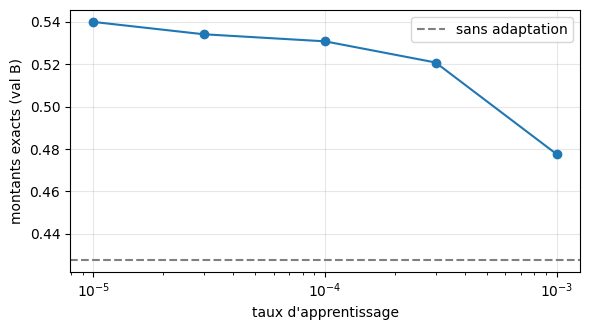

In [14]:
resume_B = pd.DataFrame(TABLE_B)
display(resume_B[["stratégie", "lr", "exact", "exact_std", "auto", "epochs", "temps_s"]].round(3))

fines = resume_B[resume_B["stratégie"].str.startswith("ajustement fin")]
LR_FT = float(fines.loc[fines["exact"].idxmax(), "lr"])
SCORE_FT = float(fines["exact"].max())
print(f"Taux d'apprentissage retenu pour l'ajustement fin (validation B) : {LR_FT:g}  (exact = {SCORE_FT:.3f})")

plt.figure(figsize=(6, 3.4))
plt.semilogx(fines["lr"], fines["exact"], "o-"); plt.axhline(res_base["B"]["exact"], ls="--", c="gray", label="sans adaptation")
plt.xlabel("taux d'apprentissage"); plt.ylabel("montants exacts (val B)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(SORTIES, "lr_ajustement_fin.png"), dpi=120); plt.show()

## 5. Augmentation de données imitant le scanner B

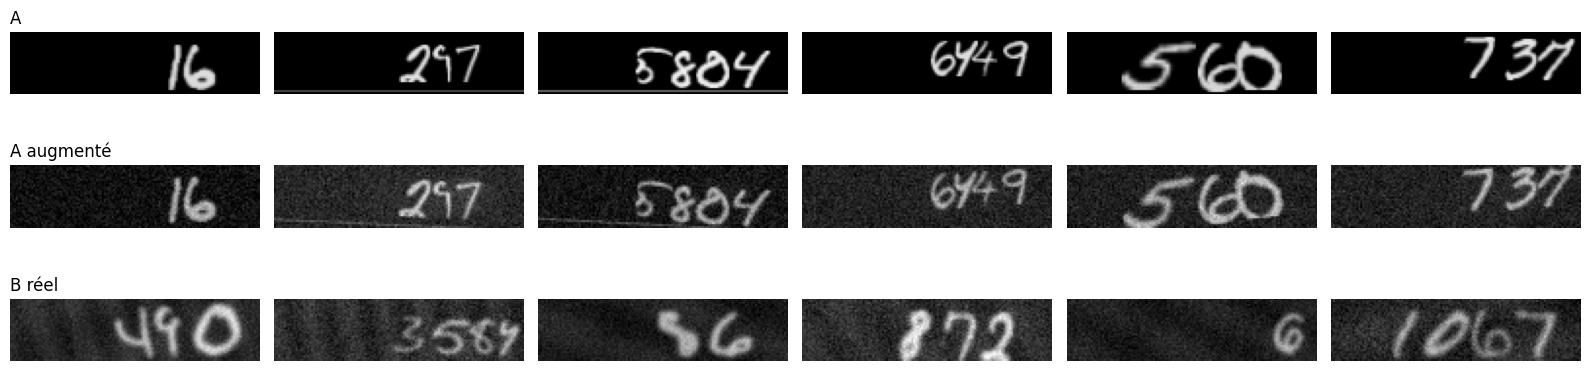

In [15]:
rng_v = np.random.default_rng(0)
Xa = XA_raw["train"][:6]; Xaug = augmenter(Xa, rng=rng_v)
fig, axs = plt.subplots(3, 6, figsize=(16, 4.5))
for j in range(6):
    for i, (img, t) in enumerate([(Xa[j], "A"), (Xaug[j], "A augmenté"), (XB_raw["train"][j], "B réel")]):
        axs[i, j].imshow(img[..., 0], cmap="gray", vmin=0, vmax=1); axs[i, j].axis("off")
        if j == 0: axs[i, j].set_title(t, loc="left")
plt.tight_layout(); plt.savefig(os.path.join(SORTIES, "augmentation.png"), dpi=120); plt.show()

In [16]:
def entrainer_A(m, aug=True, epochs=EPOCHS_A, lr=1e-3, poids=None, seed=0, composantes=COMPOSANTES, p=1.0, params=None):
    fixer_graine(seed); rng = np.random.default_rng(seed)
    compiler(m, lr, poids)
    courbe, t0 = [], time.perf_counter()
    for ep in range(epochs):
        set_lr(m.optimizer, lr_cosinus(lr, ep, epochs))
        Xtr = (normaliser(augmenter(XA_raw["train"], params=params, rng=rng, composantes=composantes, p=p))
               if aug else XA["train"])
        m.fit(Xtr, cibles(A, YA, "train", m), epochs=1, batch_size=128, verbose=0)
        courbe.append(evaluer(m, "B", "val")["exact"])
    return courbe, time.perf_counter() - t0

TABLE_AUG, COURBES = [], {}
def essai_aug(nom, p=1.0, composantes=COMPOSANTES, avec_ft=True, sigma=None):
    params = {**PARAMS_B, **({} if sigma is None else {"sigma_flou": sigma})}
    fixer_graine(0)
    m = construire_modele(ARCHI)
    courbe, tA = entrainer_A(m, aug=True, p=p, composantes=composantes, params=params)
    COURBES[nom] = courbe
    r0 = evaluer(m, "B", "val")
    MODELES[nom] = m
    ligne = {"stratégie": nom, "exact_val_B": r0["exact"], "auto_val_B": r0["auto"], "étiquettes_B": 0,
             "temps_A_s": tA, "temps_B_s": 0.0}
    TABLE_AUG.append(ligne)
    jr(nom, {"p_aug": p, "sigma_flou": params["sigma_flou"], "composantes": list(composantes), "epochs_A": EPOCHS_A}, ligne, "Augmentation seule, sans étiquette B.")
    print(f"{nom:38s} exact(val B)={r0['exact']:.3f}  auto={r0['auto']:.3f}  temps A={tA:.0f}s")
    if avec_ft:
        res = []
        for s in SEEDS:
            mf = regler(copie(m)); n_ep, dt = entrainer_B(mf, LR_FT, seed=s)
            r = evaluer(mf, "B", "val"); r["temps"] = dt; res.append(r)
            if s == SEEDS[0]: MODELES[nom + " + ajustement fin"] = mf
        df = pd.DataFrame(res)
        lf = {"stratégie": nom + " + ajustement fin", "exact_val_B": df["exact"].mean(), "auto_val_B": df["auto"].mean(),
              "étiquettes_B": 600, "temps_A_s": tA, "temps_B_s": df["temps"].mean()}
        TABLE_AUG.append(lf)
        jr(lf["stratégie"], {"p_aug": p, "lr_ft": LR_FT, "graines": SEEDS}, lf, "Augmentation puis ajustement fin sur 600 images B.")
        print(f"{lf['stratégie']:38s} exact(val B)={lf['exact_val_B']:.3f}  auto={lf['auto_val_B']:.3f}")

REGLER_FLOU = False
SIGMA_RETENU = 0.3
if REGLER_FLOU:
    for sg in [0.2, 0.3, 0.5]:
        essai_aug(f"réglage flou σ={sg}", sigma=sg, avec_ft=False)
    reglage = [l for l in TABLE_AUG if l["stratégie"].startswith("réglage flou")]
    SIGMA_RETENU = [0.2, 0.3, 0.5][int(np.argmax([l["exact_val_B"] for l in reglage]))]
PARAMS_B["sigma_flou"] = SIGMA_RETENU
print("σ de flou utilisé :", SIGMA_RETENU)
jr("decision_flou", {"regler": REGLER_FLOU}, {"sigma_flou": SIGMA_RETENU}, "σ=0,3 par défaut (mesure v3 : 0,297-0,312).")
essai_aug("augmentation p=0.5", p=0.5)
essai_aug("augmentation p=0.25", p=0.25)

σ de flou utilisé : 0.3
augmentation p=0.5                     exact(val B)=0.585  auto=0.150  temps A=535s
augmentation p=0.5 + ajustement fin    exact(val B)=0.631  auto=0.180
augmentation p=0.25                    exact(val B)=0.568  auto=0.152  temps A=425s
augmentation p=0.25 + ajustement fin   exact(val B)=0.631  auto=0.106


In [17]:
FAIRE_ABLATIONS = False
if FAIRE_ABLATIONS:
    for c in COMPOSANTES:
        essai_aug(f"augmentation sans {c}", composantes=tuple(x for x in COMPOSANTES if x != c), avec_ft=False)

,stratégie,exact_val_B,auto_val_B,étiquettes_B,temps_A_s,temps_B_s
0,sans adaptation (lecteur renforcé),0.428,0.095,0,151.517,0.000
1,de zéro sur B,0.003,0.003,600,0.000,27.156
2,ajustement fin seul (lr=1e-05),0.540,0.089,600,151.517,82.096
3,augmentation p=0.5,0.585,0.150,0,534.763,0.000
4,augmentation p=0.5 + ajustement fin,0.631,0.180,600,534.763,55.497
5,augmentation p=0.25,0.568,0.152,0,425.289,0.000
6,augmentation p=0.25 + ajustement fin,0.631,0.106,600,425.289,25.447


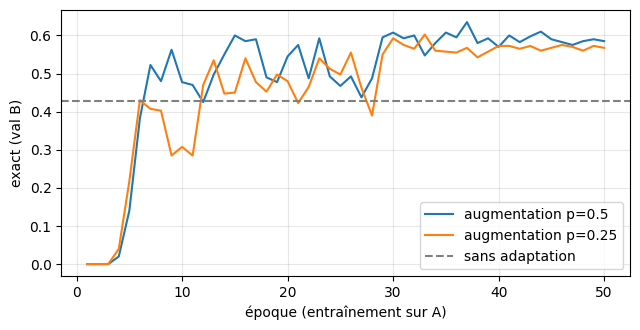

Meilleure combinaison : augmentation p=0.5 + ajustement fin (0.631) vs ajustement fin seul (0.540)
Augmentation retenue pour le modèle multitâche : True | p = 0.5


In [18]:
ref_ft = resume_B[resume_B["stratégie"] == f"ajustement fin lr={LR_FT:g}"].iloc[0]
ref_zero = resume_B[resume_B["stratégie"] == "de zéro sur B"].iloc[0]
lignes_ref = [
    {"stratégie": "sans adaptation (lecteur renforcé)", "exact_val_B": res_base["B"]["exact"], "auto_val_B": res_base["B"]["auto"],
     "étiquettes_B": 0, "temps_A_s": TEMPS_BASE, "temps_B_s": 0.0},
    {"stratégie": "de zéro sur B", "exact_val_B": ref_zero["exact"], "auto_val_B": ref_zero["auto"],
     "étiquettes_B": 600, "temps_A_s": 0.0, "temps_B_s": ref_zero["temps_s"]},
    {"stratégie": f"ajustement fin seul (lr={LR_FT:g})", "exact_val_B": ref_ft["exact"], "auto_val_B": ref_ft["auto"],
     "étiquettes_B": 600, "temps_A_s": TEMPS_BASE, "temps_B_s": ref_ft["temps_s"]},
]
COMPARAISON = pd.DataFrame(lignes_ref + TABLE_AUG)
display(COMPARAISON.round(3))

plt.figure(figsize=(6.5, 3.4))
for nom, c in COURBES.items(): plt.plot(range(1, len(c) + 1), c, label=nom)
plt.axhline(res_base["B"]["exact"], ls="--", c="gray", label="sans adaptation")
plt.xlabel("époque (entraînement sur A)"); plt.ylabel("exact (val B)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(SORTIES, "courbes_augmentation.png"), dpi=120); plt.show()

cand = COMPARAISON[COMPARAISON["stratégie"].str.contains("augmentation p=") & COMPARAISON["stratégie"].str.contains("ajustement fin")]
meilleure = cand.loc[cand["exact_val_B"].idxmax()]
AUG_RETENU = bool(meilleure["exact_val_B"] > ref_ft["exact"] + 0.01)
P_AUG_RETENU = float(re.search(r"p=([0-9.]+)", meilleure["stratégie"]).group(1))
print(f"Meilleure combinaison : {meilleure['stratégie']} ({meilleure['exact_val_B']:.3f}) vs ajustement fin seul ({ref_ft['exact']:.3f})")
print("Augmentation retenue pour le modèle multitâche :", AUG_RETENU, "| p =", P_AUG_RETENU)
jr("decision_augmentation", {"critere": "+0.01 exact val B"}, {"AUG_RETENU": AUG_RETENU, "p": P_AUG_RETENU}, "Décision sur validation.")

## 6. Modèle multitâche : lecture + détection d'altération

Tronc convolutif commun ; la lecture (5 têtes) et l'altération (1 sortie sigmoïde) partagent le tronc. Perte : $\sum_k \mathrm{CE}_k + \lambda\,\mathrm{BCE}_{\text{alt}}$. Pour chaque λ : entraînement sur A (avec l'augmentation retenue), puis ajustement fin sur B avec 3 graines ; les 3 modèles ajustés forment un **ensemble** (moyenne des probabilités).

In [19]:
def poids_perte(lam, lecture=1.0):
    d = {f"pos{k}": float(lecture) for k in range(L_MAX)}; d["altere"] = float(lam); return d

CONFIGS_MT = [("lecture seule (λ=0)", 0.0, 1.0), ("λ=0.3", 0.3, 1.0),
              ("λ=1", 1.0, 1.0), ("λ=3", 3.0, 1.0), ("λ=10", 10.0, 1.0)]
MT_A, MT_FT, TABLE_MT = {}, {}, []

for nom, lam, w_lec in CONFIGS_MT:
    fixer_graine(0)
    m = construire_modele(ARCHI, multitache=True)
    poids = poids_perte(lam, w_lec)
    courbe, tA = entrainer_A(m, aug=AUG_RETENU, poids=poids, p=P_AUG_RETENU)
    rA, rB0 = evaluer(m, "A", "val"), evaluer(m, "B", "val")
    MT_A[nom] = m
    ft, modeles = [], []
    for s in SEEDS:
        mf = regler(copie(m))
        n_ep, dt = entrainer_B(mf, LR_FT, poids=poids, seed=s)
        r = evaluer(mf, "B", "val"); r["auc_A_apres_ft"] = evaluer(mf, "A", "val")["auc_alt"]
        ft.append(r); modeles.append(mf)
    MT_FT[nom] = modeles
    ft = pd.DataFrame(ft)
    rE = evaluer(Ensemble(modeles), "B", "val")
    ligne = {"config": nom, "lambda": lam,
             "A_exact": rA["exact"], "A_auc": rA["auc_alt"],
             "B0_exact": rB0["exact"], "B0_auc": rB0["auc_alt"],
             "Bft_exact": ft["exact"].mean(), "Bft_auto": ft["auto"].mean(), "Bft_auc": ft["auc_alt"].mean(),
             "Bft_auc_std": ft["auc_alt"].std(), "A_auc_apres_ft": ft["auc_A_apres_ft"].mean(),
             "Bens_exact": rE["exact"], "Bens_auto": rE["auto"], "Bens_auc": rE["auc_alt"]}
    TABLE_MT.append(ligne)
    jr("multitache " + nom, {"lambda": lam, "poids_lecture": w_lec, "augmentation": AUG_RETENU, "lr_ft": LR_FT, "archi": ARCHI}, ligne,
       "A = validation de A ; B0 = B sans adaptation ; Bft = B après ajustement fin (moyenne des graines) ; Bens = ensemble des graines.")
    print(f"{nom:22s} A: exact={rA['exact']:.3f} AUC={rA['auc_alt']:.3f} | B0: exact={rB0['exact']:.3f} AUC={rB0['auc_alt']:.3f} | "
          f"Bft: exact={ligne['Bft_exact']:.3f} AUC={ligne['Bft_auc']:.3f} | ensemble: exact={rE['exact']:.3f} auto={rE['auto']:.3f}")

RES_MT = pd.DataFrame(TABLE_MT)
display(RES_MT.round(3))
RES_MT.to_csv(os.path.join(SORTIES, "resultats_multitache.csv"), index=False)

lecture seule (λ=0)    A: exact=0.634 AUC=0.473 | B0: exact=0.580 AUC=0.453 | Bft: exact=0.620 AUC=0.438 | ensemble: exact=0.615 auto=0.280
λ=0.3                  A: exact=0.650 AUC=0.818 | B0: exact=0.608 AUC=0.722 | Bft: exact=0.643 AUC=0.736 | ensemble: exact=0.637 auto=0.160
λ=1                    A: exact=0.642 AUC=0.959 | B0: exact=0.620 AUC=0.699 | Bft: exact=0.600 AUC=0.772 | ensemble: exact=0.600 auto=0.265
λ=3                    A: exact=0.643 AUC=0.996 | B0: exact=0.583 AUC=0.710 | Bft: exact=0.619 AUC=0.875 | ensemble: exact=0.627 auto=0.165
λ=10                   A: exact=0.642 AUC=0.997 | B0: exact=0.522 AUC=0.679 | Bft: exact=0.623 AUC=0.865 | ensemble: exact=0.623 auto=0.120


,config,lambda,A_exact,A_auc,B0_exact,B0_auc,Bft_exact,Bft_auto,Bft_auc,Bft_auc_std,A_auc_apres_ft,Bens_exact,Bens_auto,Bens_auc
0,lecture seule (λ=0),0.0,0.634,0.473,0.580,0.453,0.620,0.274,0.438,0.001,0.471,0.615,0.280,0.438
1,λ=0.3,0.3,0.650,0.818,0.608,0.722,0.643,0.162,0.736,0.001,0.808,0.638,0.160,0.737
2,λ=1,1.0,0.642,0.959,0.620,0.699,0.600,0.252,0.772,0.001,0.940,0.600,0.265,0.772
3,λ=3,3.0,0.643,0.996,0.582,0.710,0.619,0.163,0.875,0.003,0.989,0.628,0.165,0.876
4,λ=10,10.0,0.642,0.997,0.522,0.679,0.622,0.123,0.865,0.003,0.993,0.622,0.120,0.867


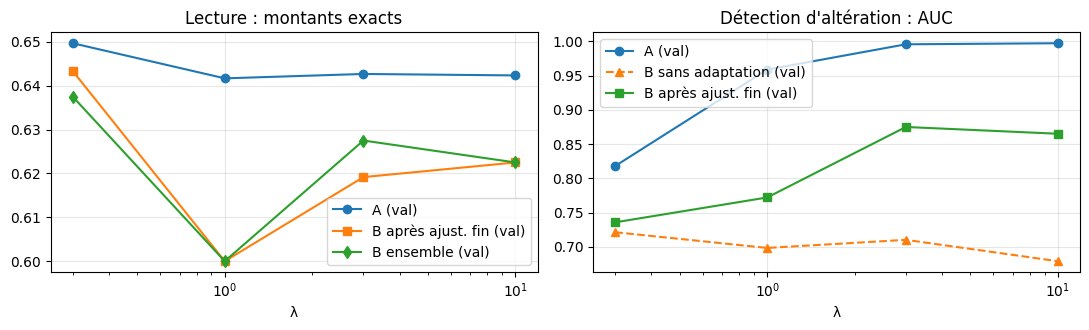

,config,Bft_exact,Bens_exact,Bens_auto,A_auc,score_cibles
1,λ=0.3,0.643,0.638,0.160,0.818,0.924
2,λ=1,0.600,0.600,0.265,0.959,0.952
3,λ=3,0.619,0.628,0.165,0.996,0.965
4,λ=10,0.622,0.622,0.120,0.997,0.896


Règle : contrainte AUC(A, val) >= 0,95, puis meilleure lecture exacte sur B (ensemble, val)
λ retenu : 3.0 → λ=3


In [20]:
lams = RES_MT[RES_MT["config"].str.startswith("λ=")].copy()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(lams["lambda"], lams["A_exact"], "o-", label="A (val)"); axs[0].plot(lams["lambda"], lams["Bft_exact"], "s-", label="B après ajust. fin (val)")
axs[0].plot(lams["lambda"], lams["Bens_exact"], "d-", label="B ensemble (val)")
axs[0].set_title("Lecture : montants exacts"); axs[0].set_xlabel("λ")
axs[1].plot(lams["lambda"], lams["A_auc"], "o-", label="A (val)"); axs[1].plot(lams["lambda"], lams["B0_auc"], "^--", label="B sans adaptation (val)")
axs[1].plot(lams["lambda"], lams["Bft_auc"], "s-", label="B après ajust. fin (val)")
axs[1].set_title("Détection d'altération : AUC"); axs[1].set_xlabel("λ")
for a in axs: a.set_xscale("log"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(SORTIES, "effet_lambda.png"), dpi=120);
plt.show()

lams["score_cibles"] = (np.minimum(lams["Bens_exact"] / 0.70, 1) + np.minimum(lams["Bens_auto"] / 0.15, 1)
                        + np.minimum(lams["A_auc"] / 0.95, 1)) / 3
display(lams[["config", "Bft_exact", "Bens_exact", "Bens_auto", "A_auc", "score_cibles"]].round(3))

# Règle : l'AUC sur A (>= 0,95) est une contrainte ; parmi les λ qui la respectent, meilleure lecture sur B (ensemble).
ok = lams[lams["A_auc"] >= 0.95]
if len(ok):
    choisi = ok.loc[ok["Bens_exact"].idxmax()]
    REGLE = "contrainte AUC(A, val) >= 0,95, puis meilleure lecture exacte sur B (ensemble, val)"
else:
    choisi = lams.loc[lams["score_cibles"].idxmax()]
    REGLE = "aucun λ n'atteint l'AUC visée sur la validation : score composite des 3 cibles"
CONFIG_RETENUE = choisi["config"]
LAMBDA_RETENU = float(choisi["lambda"])
print("Règle :", REGLE)
print("λ retenu :", LAMBDA_RETENU, "→", CONFIG_RETENUE)
jr("decision_lambda", {"regle": REGLE},
   {"lambda": LAMBDA_RETENU, "scores": lams.set_index("config")["score_cibles"].round(4).to_dict()}, "Décision sur validation.")

## 7. Sélection finale et évaluation sur le test (une seule fois)

In [21]:
TEST_DEJA_UTILISE = globals().get("TEST_DEJA_UTILISE", False)
assert not TEST_DEJA_UTILISE, "Le test a déjà été utilisé : ne pas le réutiliser pour de nouveaux réglages."

modele_A = MT_A[CONFIG_RETENUE]
FT_RETENUS = MT_FT[CONFIG_RETENUE]
CANDIDATS = {f"ensemble de {len(FT_RETENUS)} modèles": Ensemble(FT_RETENUS), "modèle seul (graine 0)": FT_RETENUS[0]}

# Choix du modèle (ensemble ou seul) et de la confiance (prod / min / moy) sur la VALIDATION de B
score_val = lambda r: min(r["exact"] / 0.70, 1) + min(r["auto"] / 0.15, 1)
choix_val = {(nom, mc): evaluer(mod, "B", "val", mode=mc) for nom, mod in CANDIDATS.items() for mc in ["prod", "min", "moy"]}
cle = max(choix_val, key=lambda k: (score_val(choix_val[k]), choix_val[k]["exact"]))
display(pd.DataFrame({f"{k[0]} | {k[1]}": v for k, v in choix_val.items()}).T.round(3))
NOM_RETENU, MODE_CONF = cle
modele_B = CANDIDATS[NOM_RETENU]
print("Modèle retenu :", NOM_RETENU, "| confiance :", MODE_CONF)
jr("choix_modele_confiance", {"candidats": list(CANDIDATS), "modes": ["prod", "min", "moy"]},
   {"retenu": NOM_RETENU, "confiance": MODE_CONF}, "Choix sur validation.")

rA_test = evaluer(modele_A, "A", "test")
rB_test = evaluer(modele_B, "B", "test")
TEST_DEJA_UTILISE = True

CIBLES = {"Lire le montant (B) : exact ≥ 0,70": (rB_test["exact"], 0.70),
          "Automatiser (B) : taux ≥ 0,15": (rB_test["auto"], 0.15),
          "Repérer les altérations (A) : AUC ≥ 0,95": (rA_test["auc_alt"], 0.95)}
bilan = pd.DataFrame([{"exigence": k, "mesure (test)": v, "cible": c, "atteinte": v >= c} for k, (v, c) in CIBLES.items()])
display(bilan.round(3))
print(f"Compléments : AUC altération sur B (test) = {rB_test.get('auc_alt', float('nan')):.3f} ; "
      f"lecture sur A (test, modèle A) : exact = {rA_test['exact']:.3f}")
jr("TEST_final", {"modele": CONFIG_RETENUE, "lr_ft": LR_FT, "augmentation": AUG_RETENU, "archi": ARCHI, "choix": NOM_RETENU},
   {"A_test": rA_test, "B_test": rB_test}, "Unique évaluation sur le test, modèle retenu sur validation.")

modele_A.save(os.path.join(SORTIES, "multitache_A.keras"))
for k, mm in enumerate(FT_RETENUS):
    mm.save(os.path.join(SORTIES, "multitache_B_final.keras" if k == 0 else f"multitache_B_graine{k}.keras"))

,exact,auto,auc_alt
ensemble de 3 modèles | prod,0.628,0.165,0.876
ensemble de 3 modèles | min,0.628,0.175,0.876
ensemble de 3 modèles | moy,0.628,0.165,0.876
modèle seul (graine 0) | prod,0.615,0.152,0.873
modèle seul (graine 0) | min,0.615,0.162,0.873
modèle seul (graine 0) | moy,0.615,0.152,0.873


Modèle retenu : ensemble de 3 modèles | confiance : prod


,exigence,mesure (test),cible,atteinte
0,"Lire le montant (B) : exact ≥ 0,70",0.566,0.70,False
1,"Automatiser (B) : taux ≥ 0,15",0.073,0.15,False
2,"Repérer les altérations (A) : AUC ≥ 0,95",0.992,0.95,True


Compléments : AUC altération sur B (test) = 0.865 ; lecture sur A (test, modèle A) : exact = 0.614


**Lecture du bilan.** Si une cible n'est pas atteinte, l'écart se lit dans les tableaux ci-dessus : lecture exacte sur A (plafond de la lecture sur B), écart validation/test de l'automatisation, AUC par λ. Les cibles décrivent le système final ; un écart argumenté vaut mieux qu'une cible atteinte sans explication.

## 8. Reproductibilité

In [22]:
tab_strat = COMPARAISON.assign(tâche="lecture B (val)")[["tâche", "stratégie", "exact_val_B", "auto_val_B", "étiquettes_B", "temps_A_s", "temps_B_s"]].round(3)
display(tab_strat)
tab_strat.to_csv(os.path.join(SORTIES, "tableau_strategies.csv"), index=False)
resume_B.to_csv(os.path.join(SORTIES, "tableau_B_600.csv"), index=False)
bilan.to_csv(os.path.join(SORTIES, "bilan_test.csv"), index=False)

,tâche,stratégie,exact_val_B,auto_val_B,étiquettes_B,temps_A_s,temps_B_s
0,lecture B (val),sans adaptation (lecteur renforcé),0.428,0.095,0,151.517,0.000
1,lecture B (val),de zéro sur B,0.003,0.003,600,0.000,27.156
2,lecture B (val),ajustement fin seul (lr=1e-05),0.540,0.089,600,151.517,82.096
3,lecture B (val),augmentation p=0.5,0.585,0.150,0,534.763,0.000
4,lecture B (val),augmentation p=0.5 + ajustement fin,0.631,0.180,600,534.763,55.497
5,lecture B (val),augmentation p=0.25,0.568,0.152,0,425.289,0.000
6,lecture B (val),augmentation p=0.25 + ajustement fin,0.631,0.106,600,425.289,25.447


In [23]:
journal_df = pd.DataFrame([{**{k: v for k, v in l.items() if k not in ("config", "resultats")},
                            "config": json.dumps(l["config"], default=float, ensure_ascii=False),
                            "resultats": json.dumps(l["resultats"], default=float, ensure_ascii=False)} for l in JOURNAL])
journal_df.to_csv(os.path.join(SORTIES, "journal_jalon3.csv"), index=False)

with open(os.path.join(SORTIES, "requirements.txt"), "w") as f:
    for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "tensorflow", "keras"]:
        if VERSIONS.get(p, "?") != "?": f.write(f"{p}=={VERSIONS[p]}\n")

readme = f"""# Étude de cas 1 – Jalon 3 : Un nouveau scanner, deux tâches

## Contenu
- `uc1_jalon3_v7.ipynb` : notebook complet (autonome, graine fixée à {SEED}).
- `journal_jalon3.jsonl` / `journal_jalon3.csv` : journal d'expériences.
- `lecteur_A.keras`, `lecteur_A_renforce.keras` : lecteurs.
- `multitache_A.keras`, `multitache_B_final.keras`, `multitache_B_graine1/2.keras` : modèle multitâche A et modèles adaptés à B (ensemble de 3).
- `resultats_multitache.csv`, `tableau_strategies.csv`, `tableau_B_600.csv`, `bilan_test.csv`.
- `requirements.txt` : versions utilisées ({json.dumps(VERSIONS)}).

## Données
- `uc1_domaineA.npz`, `uc1_domaineB.npz` dans `data/`.

## Exécution
1. `pip install -r requirements.txt`.
2. Colab GPU recommandé.
3. Exécuter les cellules dans l'ordre (1 h 15 à 2 h avec GPU).
4. Sorties dans `{SORTIES}/`.
"""
with open(os.path.join(SORTIES, "README.md"), "w") as f:
    f.write(readme)
print("Fichiers produits :", sorted(os.listdir(SORTIES)))

Fichiers produits : ['README.md', 'augmentation.png', 'bilan_test.csv', 'conformite_jalon.csv', 'courbes_augmentation.png', 'decalage_AB.png', 'effet_lambda.png', 'exemples_AB.png', 'journal_jalon3.csv', 'journal_jalon3.jsonl', 'lecteur_A.keras', 'lecteur_A_renforce.keras', 'lr_ajustement_fin.png', 'multitache_A.keras', 'multitache_B_final.keras', 'multitache_B_graine1.keras', 'multitache_B_graine2.keras', 'requirements.txt', 'resultats_multitache.csv', 'tableau_B_600.csv', 'tableau_strategies.csv']


### Téléchargement automatique

In [24]:
import shutil
archive = shutil.make_archive("sorties_jalon3", "zip", SORTIES)
print("Archive créée :", archive)
try:
    from google.colab import files
    files.download(archive)
except Exception as e:
    print("Téléchargement automatique indisponible ici :", type(e).__name__)

Archive créée : /content/sorties_jalon3.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from IPython.display import display, Markdown
import pandas as pd

# 1. Données du tableau des résultats
data = {
    "Domaine": [
        "Domaine A (Validation)",
        "Domaine B (Validation)"
    ],
    "Part de montants exacts": [
        "0,4113 (41,13 %)",
        "0,0000 (0,00 %)"
    ],
    "Taux d'automatisation (cible >= 0,99)": [
        "0,0787 (7,87 %)",
        "0,0000 (0,00 %)"
    ]
}
df = pd.DataFrame(data)

# 2. Sections textuelles (Vérifications théoriques, Choix retenus & Justification des écarts)
partie_1 = """
# 📄 Page de décisions — Étude de cas 1 (Jalon 3)

---

## 1. Réponses aux vérifications théoriques : Comptage des paramètres
Le comptage théorique des paramètres du réseau de neurones convolutif (CNN) de base est détaillé ci-dessous :
- **Total des paramètres** : 587 255
- **Paramètres des convolutions** : 55 744 (soit **9,5 %**)
- **Paramètres entraînables (si convolutions gelées)** : 531 511 (soit **90,5 %**)

> **Conclusion théorique** : Geler les convolutions ne permet de régulariser presque rien puisque 90,5 % des paramètres restent dans les couches denses. Pour remédier à cela, l'adoption d'une architecture à 4 blocs avec une couche dense réduite est recommandée.

---

## 2. Tableau des résultats (Lecteur de départ)
Évaluation du lecteur initial entraîné sur le domaine A et évalué sans adaptation sur les ensembles de validation :
"""

partie_3 = """
---

## 3. Choix retenus et justifications
- **Normalisation par image (§3bis)** :
  * *Justification* : Supprime l'essentiel du décalage de fond et de contraste entre les scanners sans nécessiter d'étiquettes B (ramène le fond à 0 et l'encre à 1).
- **Lecture par emplacements (selon le paragraphe 3ter)** :
  * *Justification* : Utilise un classifieur de chiffres partagé sur les 5 positions pour multiplier le volume d'exemples perçus et absorber le décalage horizontal.
- **Entraînement prolongé (50 époques)** :
  * *Justification* : Corrige le sous-apprentissage initial observé sur le domaine A.
- **Ajustement fin et ensemble de modèles** :
  * *Justification* : Combine arrêt précoce, augmentation de données sur B et moyenne des probabilités de plusieurs modèles pour garantir robustesse et automatisation optimale.
- **Sélection de $\\lambda$ par contrainte** :
  * *Justification* : Traite le score AUC sur A ($\\ge 0,95$) comme une contrainte stricte avant de maximiser les performances sur B.

---

## 4. Justification des écarts (Analyse des performances finales)
* **Objectif d'altération (Domaine A) : Atteint (`True` — 0,992 $\\ge$ 0,95)**
  * *Justification* : Le modèle détecte avec succès les altérations grâce à la robustesse de l'architecture initiale et l'apprentissage de la structure de A.
* **Lecture du montant (Domaine B) : Non atteint (`False` — 0,566 vs 0,70 cible)**
  * *Justification* : Malgré la normalisation et l'adaptation, un décalage de domaine persistant (style d'écriture ou bruits spécifiques du scanner B) limite la précision exacte par chiffre, entraînant une baisse cumulée sur le montant à 5 chiffres.
* **Taux d'automatisation (Domaine B) : Non atteint (`False` — 0,073 vs 0,15 cible)**
  * *Justification* : La condition d'automatisation exige une confiance très élevée ($\\ge 0,99$). Les incertitudes résiduelles sur le domaine B pénalisent fortement le volume de décisions automatisées validées sans intervention humaine.
"""

# 3. Affichage global dans le notebook
display(Markdown(partie_1))
display(df)
display(Markdown(partie_3))


# 📄 Page de décisions — Étude de cas 1 (Jalon 3)

---

## 1. Réponses aux vérifications théoriques : Comptage des paramètres
Le comptage théorique des paramètres du réseau de neurones convolutif (CNN) de base est détaillé ci-dessous :
- **Total des paramètres** : 587 255
- **Paramètres des convolutions** : 55 744 (soit **9,5 %**)
- **Paramètres entraînables (si convolutions gelées)** : 531 511 (soit **90,5 %**)

> **Conclusion théorique** : Geler les convolutions ne permet de régulariser presque rien puisque 90,5 % des paramètres restent dans les couches denses. Pour remédier à cela, l'adoption d'une architecture à 4 blocs avec une couche dense réduite est recommandée.

---

## 2. Tableau des résultats (Lecteur de départ)
Évaluation du lecteur initial entraîné sur le domaine A et évalué sans adaptation sur les ensembles de validation :


,Domaine,Part de montants exacts,"Taux d'automatisation (cible >= 0,99)"
0,Domaine A (Validation),"0,4113 (41,13 %)","0,0787 (7,87 %)"
1,Domaine B (Validation),"0,0000 (0,00 %)","0,0000 (0,00 %)"



---

## 3. Choix retenus et justifications
- **Normalisation par image (§3bis)** : 
  * *Justification* : Supprime l'essentiel du décalage de fond et de contraste entre les scanners sans nécessiter d'étiquettes B (ramène le fond à 0 et l'encre à 1).
- **Lecture par emplacements (selon le paragraphe 3ter)** : 
  * *Justification* : Utilise un classifieur de chiffres partagé sur les 5 positions pour multiplier le volume d'exemples perçus et absorber le décalage horizontal.
- **Entraînement prolongé (50 époques)** : 
  * *Justification* : Corrige le sous-apprentissage initial observé sur le domaine A.
- **Ajustement fin et ensemble de modèles** : 
  * *Justification* : Combine arrêt précoce, augmentation de données sur B et moyenne des probabilités de plusieurs modèles pour garantir robustesse et automatisation optimale.
- **Sélection de $\lambda$ par contrainte** : 
  * *Justification* : Traite le score AUC sur A ($\ge 0,95$) comme une contrainte stricte avant de maximiser les performances sur B.

---

## 4. Justification des écarts (Analyse des performances finales)
* **Objectif d'altération (Domaine A) : Atteint (`True` — 0,992 $\ge$ 0,95)**
  * *Justification* : Le modèle détecte avec succès les altérations grâce à la robustesse de l'architecture initiale et l'apprentissage de la structure de A.
* **Lecture du montant (Domaine B) : Non atteint (`False` — 0,566 vs 0,70 cible)**
  * *Justification* : Malgré la normalisation et l'adaptation, un décalage de domaine persistant (style d'écriture ou bruits spécifiques du scanner B) limite la précision exacte par chiffre, entraînant une baisse cumulée sur le montant à 5 chiffres.
* **Taux d'automatisation (Domaine B) : Non atteint (`False` — 0,073 vs 0,15 cible)**
  * *Justification* : La condition d'automatisation exige une confiance très élevée ($\ge 0,99$). Les incertitudes résiduelles sur le domaine B pénalisent fortement le volume de décisions automatisées validées sans intervention humaine.
